# 03a — Algorithm Scan (Phase 1)

**Goal:** Quickly evaluate 10 algorithm families with sensible defaults using
cross-validated PR-AUC, then rank them to identify top candidates for
Optuna hyperparameter tuning in notebook 03b.

**Why PR-AUC as the primary metric?**
- Threshold-independent — not gameable by lowering the decision boundary
- Robust to class imbalance (26.5% positive rate) unlike ROC-AUC
- Directly measures the precision-recall trade-off that matters for churn

**Pipeline position:**
```
01_eda → 02_feature_engineering → [THIS NOTEBOOK] → 03b_tuning → 03c_evaluation
```

**Output:** `data/processed/phase1_scan_results.csv` — sorted algorithm rankings
consumed by 03b to select tuning candidates.

## 0. Setup & Imports

In [1]:
import os
import sys
import warnings
from pathlib import Path
from time import perf_counter

warnings.filterwarnings("ignore")

# ── Project root resolution ───────────────────────────────────────────────────
def find_project_root(marker: str = "pyproject.toml") -> Path:
    current = Path.cwd()
    for parent in [current, *current.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"Could not locate project root from {current}")

PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root : {PROJECT_ROOT}")

# ── Third-party ───────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# ── Project modules ────────────────────────────────────────────────────────────
from src.data.ingest import load_for_training
from src.data.validate import validate_raw_data
from src.data.preprocess import run_preprocessing
from src.models.pipeline import build_baseline_pipeline
from src.utils.logging import get_logger
from src.utils.config_loader import get_config

logger = get_logger(__name__)
cfg    = get_config()

# ── Global constants ──────────────────────────────────────────────────────────
RANDOM_STATE = cfg.training.random_state
CV_FOLDS     = cfg.training.cv_folds
TEST_SIZE    = cfg.training.test_size
FN_COST      = cfg.model.cost_matrix.false_negative_cost  # $500
FP_COST      = cfg.model.cost_matrix.false_positive_cost  # $20

# ── Plotting ──────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 120})

print(f"Config  → random_state={RANDOM_STATE}, cv_folds={CV_FOLDS}, test_size={TEST_SIZE}")
print(f"Gates   → min_roc_auc={cfg.model.performance_gates.min_roc_auc}, "
      f"min_pr_auc={cfg.model.performance_gates.min_pr_auc}, "
      f"min_recall={cfg.model.performance_gates.min_recall_at_threshold}")
print(f"Costs   → FN=${FN_COST:.0f}, FP=${FP_COST:.0f}")

Project root : /home/deepak/customer-churn-mlops


Config  → random_state=42, cv_folds=5, test_size=0.2
Gates   → min_roc_auc=0.82, min_pr_auc=0.65, min_recall=0.7
Costs   → FN=$500, FP=$20


## 1. Data Loading & Preprocessing

In [2]:
raw_df    = load_for_training()
validated = validate_raw_data(raw_df)
X, y      = run_preprocessing(validated)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Full dataset  : X={X.shape}  |  churn rate {y.mean()*100:.1f}%  ({y.sum()} churners)")
print(f"Train         : {X_train.shape[0]} rows  |  churn {y_train.mean()*100:.1f}%")
print(f"Test          : {X_test.shape[0]} rows   |  churn {y_test.mean()*100:.1f}%")

2026-10-10 10:40:29 | INFO     | src.data.ingest | Loading training data from default path.


2026-10-10 10:40:29 | INFO     | src.data.ingest | Loading raw data from: /home/deepak/customer-churn-mlops/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv


2026-10-10 10:40:29 | INFO     | src.data.ingest | Loaded raw data — shape: (7043, 21), columns: 21, memory: 7.8 MB


2026-10-10 10:40:29 | INFO     | src.data.validate | Starting raw data validation on DataFrame with shape (7043, 21).


2026-10-10 10:40:29 | INFO     | src.data.validate | fix_total_charges: found 11 blank TotalCharges rows (dtype was object). Imputing with MonthlyCharges.


...

2026-10-10 10:40:29 | INFO     | src.data.preprocess | Encoded target 'Churn': 1869 positives (churn=1), 5174 negatives (churn=0).


2026-10-10 10:40:29 | INFO     | src.data.preprocess | Dropped columns: ['customerID']


2026-10-10 10:40:29 | INFO     | src.data.preprocess | Preprocessing complete. Output shape: (7043, 20).


2026-10-10 10:40:29 | INFO     | src.data.preprocess | Split complete — X shape: (7043, 19), y shape: (7043,), positive rate: 26.54%.


Full dataset  : X=(7043, 19)  |  churn rate 26.5%  (1869 churners)
Train         : 5634 rows  |  churn 26.5%
Test          : 1409 rows   |  churn 26.5%


## 2. Define Algorithm Candidates

Quick 5-fold CV with sensible (not exhaustively tuned) defaults.
Purpose: rank algorithm *families* by PR-AUC ceiling and eliminate weak
candidates before spending Optuna budget.

**Critical design note:** All models here use `class_weight='balanced'` or
`scale_pos_weight` to handle the 26.5% minority class. Without this, every
model defaults to predicting "retain" and gets a high accuracy but useless PR-AUC.

In [3]:
SCAN_ESTIMATORS: dict = {

    # ── Trivial floor ─────────────────────────────────────────────────────
    "Dummy": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),

    # ── Linear ────────────────────────────────────────────────────────────
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", C=1.0, max_iter=3000,
        solver="saga", penalty="l2", random_state=RANDOM_STATE,
    ),

    # ── Tree-based ────────────────────────────────────────────────────────
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=6, min_samples_leaf=30,
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, max_depth=None, min_samples_leaf=5,
        class_weight="balanced_subsample", max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400, max_depth=None, min_samples_leaf=5,
        class_weight="balanced_subsample", max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, min_samples_leaf=20, random_state=RANDOM_STATE,
    ),

    # ── SVM (calibrated for probabilities) ───────────────────────────────
    "SVC (calibrated)": CalibratedClassifierCV(
        SVC(kernel="rbf", class_weight="balanced", C=1.0,
            gamma="scale", random_state=RANDOM_STATE),
        method="isotonic", cv=3,
    ),

    # ── Gradient boosting trio — the real contenders ──────────────────────
    "XGBoost": XGBClassifier(
        n_estimators=500, learning_rate=0.05, max_depth=5,
        scale_pos_weight=2.76,  # neg/pos ratio
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
        eval_metric="logloss", verbosity=0,
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=500, learning_rate=0.05, num_leaves=63,
        scale_pos_weight=2.76, min_child_samples=20,
        subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0,
        random_state=RANDOM_STATE, verbose=-1, n_jobs=-1,
    ),
    "CatBoost": CatBoostClassifier(
        iterations=500, learning_rate=0.05, depth=6,
        auto_class_weights="Balanced", l2_leaf_reg=3.0,
        random_seed=RANDOM_STATE, verbose=0,
    ),
}

print(f"Phase 1 — scanning {len(SCAN_ESTIMATORS)} algorithms with {CV_FOLDS}-fold CV...")

Phase 1 — scanning 10 algorithms with 5-fold CV...


## 3. Run Phase 1 Cross-Validation

In [4]:
cv_splitter = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
phase1_results: dict[str, dict] = {}

for name, estimator in SCAN_ESTIMATORS.items():
    pipeline = build_baseline_pipeline(estimator)
    t0 = perf_counter()
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv_splitter,
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
        n_jobs=1, return_train_score=False,
    )
    elapsed = perf_counter() - t0

    phase1_results[name] = {
        "cv_roc_auc_mean" : round(scores["test_roc_auc"].mean(), 4),
        "cv_roc_auc_std"  : round(scores["test_roc_auc"].std(),  4),
        "cv_pr_auc_mean"  : round(scores["test_pr_auc"].mean(),  4),
        "cv_pr_auc_std"   : round(scores["test_pr_auc"].std(),   4),
        "scan_time_s"     : round(elapsed, 1),
    }

    print(
        f"  {name:<26} | "
        f"PR-AUC {scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f} | "
        f"ROC-AUC {scores['test_roc_auc'].mean():.4f} | "
        f"{elapsed:.0f}s"
    )

2026-10-10 10:40:29 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (4507, 19).


2026-10-10 10:40:29 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (4507, 47). Added 28 new columns.


[LightGBM] [Info] Number of positive: 1196, number of negative: 3311
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001146 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1525
[LightGBM] [Info] Number of data points in the train set: 4507, number of used features: 80
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265365 -> initscore=-1.018268
[LightGBM] [Info] Start training from score -1.018268


2026-10-10 10:40:29 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1127, 19).


2026-10-10 10:40:29 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1127, 47). Added 28 new columns.


...

2026-10-10 10:41:37 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (4508, 19).


2026-10-10 10:41:37 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (4508, 47). Added 28 new columns.


2026-10-10 10:41:38 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1126, 19).


2026-10-10 10:41:38 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1126, 47). Added 28 new columns.


  CatBoost                   | PR-AUC 0.6440 ± 0.0196 | ROC-AUC 0.8370 | 6s


In [5]:
phase1_df = (
    pd.DataFrame(phase1_results).T.reset_index().rename(columns={"index": "model"})
    .sort_values("cv_pr_auc_mean", ascending=False).reset_index(drop=True)
)
phase1_df.index += 1

print("\n── Phase 1 Scan Results (sorted by CV PR-AUC) ───────────────────────")
print(phase1_df.to_string(float_format="{:.4f}".format))


── Phase 1 Scan Results (sorted by CV PR-AUC) ───────────────────────
                  model  cv_roc_auc_mean  cv_roc_auc_std  cv_pr_auc_mean  cv_pr_auc_std  scan_time_s
1   Logistic Regression           0.8478          0.0109          0.6682         0.0192       1.9000
2         Random Forest           0.8433          0.0118          0.6537         0.0215      11.1000
3     Gradient Boosting           0.8390          0.0097          0.6482         0.0126      15.4000
4           Extra Trees           0.8404          0.0092          0.6444         0.0261      10.7000
5              CatBoost           0.8370          0.0094          0.6440         0.0196       5.6000
6               XGBoost           0.8331          0.0097          0.6377         0.0168       4.6000
7         Decision Tree           0.8271          0.0133          0.6213         0.0163       0.9000
8              LightGBM           0.8244          0.0070          0.6160         0.0099       5.7000
9      SVC (calibrat

## 4. Visual Summary

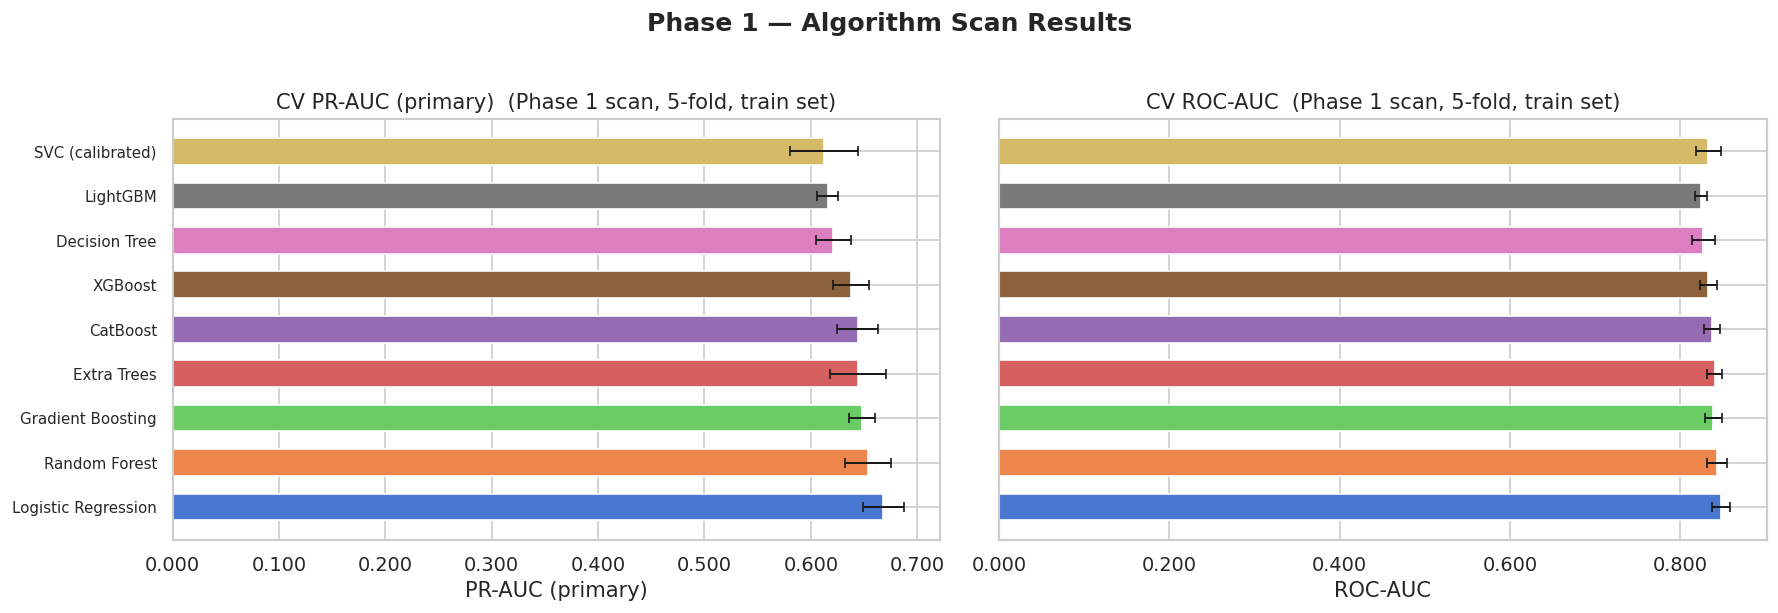

In [6]:
# Drop Dummy for visual clarity
plot_df = phase1_df[phase1_df["model"] != "Dummy"].copy().reset_index(drop=True)
colors   = sns.color_palette("muted", len(plot_df))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, metric, std_col, label in [
    (axes[0], "cv_pr_auc_mean",  "cv_pr_auc_std",  "PR-AUC (primary)"),
    (axes[1], "cv_roc_auc_mean", "cv_roc_auc_std", "ROC-AUC"),
]:
    y_pos = range(len(plot_df))
    ax.barh(
        y_pos, plot_df[metric], xerr=plot_df[std_col],
        align="center", height=0.6, color=colors,
        error_kw={"elinewidth": 1.2, "capsize": 3},
    )
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(plot_df["model"], fontsize=9)
    ax.set_xlabel(label)
    ax.set_title(f"CV {label}  (Phase 1 scan, {CV_FOLDS}-fold, train set)")
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
    ax.invert_yaxis()

plt.suptitle("Phase 1 — Algorithm Scan Results", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("reports/phase1_algorithm_scan.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Save Phase 1 Results for 03b

The results CSV is the handoff point to the hyperparameter tuning notebook.
It contains all CV metrics so 03b can select the top-N candidates.

In [7]:
output_path = Path("data/processed/phase1_scan_results.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
phase1_df.to_csv(output_path, index=False)
print(f"\n✅  Phase 1 results saved to {output_path}")
print(f"    {len(phase1_df)} algorithms scored. Top candidate: {phase1_df.iloc[0]['model']}")
print(f"\n    → Next: run 03b_hyperparameter_tuning.py")


✅  Phase 1 results saved to data/processed/phase1_scan_results.csv
    10 algorithms scored. Top candidate: Logistic Regression

    → Next: run 03b_hyperparameter_tuning.py
